# Klassificatie kleding afbeeldingen


#### Inhoud (volgends opdracht, dit kan later weg, meer voor overzicht)

- Definieer het probleem
- Verzamel de data
- Laad de data in
- Prepareer de data # slaan we over is al gedaan
- Visualiseer de data
- Splits de data
- Train het model met de trainingsdata
- Voorspel met het model de testdata
- Evalueer het model

- Deel 2: Foto van jezelf

#### Definieer het probleem

We willen een neuraal netwerk trainen dat van een afbeelding kan voorspellen op kleding type. 


#### Verzamel de data & Laad data in

Dataset komt van deze repo: https://github.com/zalandoresearch/fashion-mnist/tree/master

In de map "data/fashion" staan 4 datasets (t10k-images-idx3-ubyte,  t10k-labels-idx1-ubyte,  train-images-idx3-ubyte,  train-labels-idx1-ubyte). 
Er is al train data, dus dat hoeven wij niet meer aan te maken. 





In [17]:
import numpy as np

# headerbytes overslaan met offset
X_train = np.fromfile("train-images-idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28) # 28 pixels stond in beschrijving
y_train = np.fromfile("train-labels-idx1-ubyte", dtype=np.uint8, offset=8)

print("Aantal afbeeldingen:", X_train.shape)  # hoofdletter X want matrix!!
print("Labels van eerste 10 afbeeldingen:", y_train[:10])



Aantal afbeeldingen: (60000, 28, 28)
Labels van eerste 10 afbeeldingen: [9 0 0 3 0 2 7 2 5 5]


In [18]:
# test data inladen 

X_test = np.fromfile("t10k-images-idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28)
y_test = np.fromfile("t10k-labels-idx1-ubyte", dtype=np.uint8, offset=8)

print("Aantal testafbeeldingen:", X_test.shape)

Aantal testafbeeldingen: (10000, 28, 28)


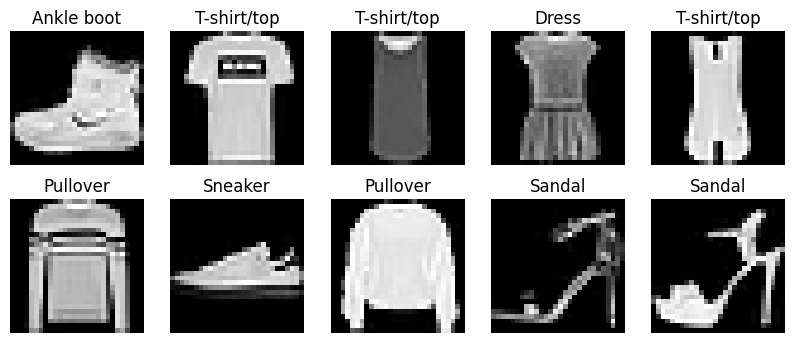

In [19]:
import matplotlib.pyplot as plt

# labels 0 t/m 9 omzetten naar namen (volgorde uit README van de repo)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Eerste 10 afbeeldingen tonen
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()

#### Prepareer de data



In [20]:
# Dit deel is volgensmij overbodig, omdat hiervoor al de data wordt ingelezen enzo, en de data is al gesplitst in
# test en training data.

#from sklearn.model_selection import train_test_split

#images = np.fromfile("t10k-images-idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28)
#labels = np.fromfile("t10k-labels-idx1-ubyte", dtype=np.uint8, offset=8)

#class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
#               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

#x_train, x_test, y_train, y_test = train_test_split(
#    images / 255.0, labels, test_size=0.2, random_state=42, stratify=labels
#)

#print(x_train.shape, x_test.shape)

In [21]:
# pixels van 0-255 naar 0-1, neuraal netwerk leert beter met kleine getallen
X_train = X_train / 255.0
X_test = X_test / 255.0

print("min:", X_train.min(), "max:", X_train.max())


min: 0.0 max: 1.0


Met grote inputwaarden worden de berekeningen in het netwerk ook groot en dan leert het model trager en minder stabiel. 
Test data moeten we natuurlijk niet vergeten.

#### Neurale netwerk bouwen

In [22]:
# pip install tensorflow
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    # 1 rij aan pixels
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    # patronen leren kennen
    layers.Dense(128, activation="relu"),
    # kans per kledingcategorie
    layers.Dense(10, activation="softmax")
])

# model compileren
model.compile(
    # Hoe het model de gewichten aanpast
    optimizer="adam",
    # hoe groot de fout van het model is
    loss="sparse_categorical_crossentropy",
    # percentage correcte voorspellingen
    metrics=["accuracy"]
)

Nu kan het model getraind worden met de trainingsdata.

In [23]:
history = model.fit(
    X_train,
    y_train,
    # 5 keer door de trainingsdata
    epochs=5,
    # gewichten worden bijgewerkt na 128 afbeeldingen
    batch_size=128,
    # 20% van de trainingsdata gebruiken om te "testen"
    validation_split=0.2
)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8009 - loss: 0.5797 - val_accuracy: 0.8428 - val_loss: 0.4491
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8501 - loss: 0.4246 - val_accuracy: 0.8597 - val_loss: 0.3983
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8632 - loss: 0.3843 - val_accuracy: 0.8442 - val_loss: 0.4190
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8716 - loss: 0.3586 - val_accuracy: 0.8702 - val_loss: 0.3647
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8809 - loss: 0.3343 - val_accuracy: 0.8737 - val_loss: 0.3547


Resultaten training:  
Het model is getraind over 5 epochs. De accuracy bij epoch 1 was 80,09% en eindigde op 88,09%. De validatie-accuracy eindigde op 87,37%. Deze waardes laten zien dat het model steeds beter werd in het herkennen en classificeren van de afbeeldingen.  
De trainings- en validatieresultaten liggen best dicht bij elkaar, er is dus waarschijnlijk geen sterke overfitting aanwezig.  
Ik ga nu het model testen met de testdata.

In [26]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test loss: ", test_loss, "Test accuracy: ", test_accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8648 - loss: 0.3809
Test loss:  0.38089126348495483 Test accuracy:  0.864799976348877


Evaluatie op de testdata:  
De accuracy van de voorspellingen van het model op de testdata is 86,48% en de loss is 0,3809.  
Deze testresultaten liggen redelijk dichtbij de validatieresultaten, dit betekent dat het model ook goed kan omgaan met afbeeldingen die hij nog niet eerder heeft gezien.  

Hier is de visualisatie van deze resultaten:

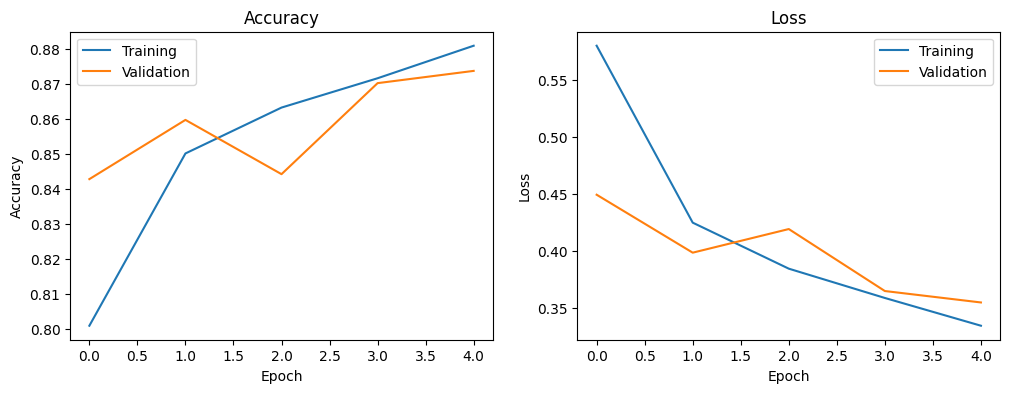

In [27]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

Je ziet in deze grafieken dat de accuracy in een stijgende lijn gaat en de loss in een dalende lijn. Dit is goed, omdat het betekent dat het model leert van de data. Ik vind het wel interessant dat bij epoch 2 de lijnen allebei de verkeerde kant op gaan (de accuracy is dan lager en de loss is hoger). Dit betekent dat het model op dat moment iets minder goed presteert op de validatiedata. Dit kan komen door variatie in de data waarop het model wordt getest. In de volgende epochs herstelt dit weer en verbeteren de resultaten verder.   

Ik ga nu 10 afbeeldingen van de testset laten zien met het echte label en het voorspelde label:


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


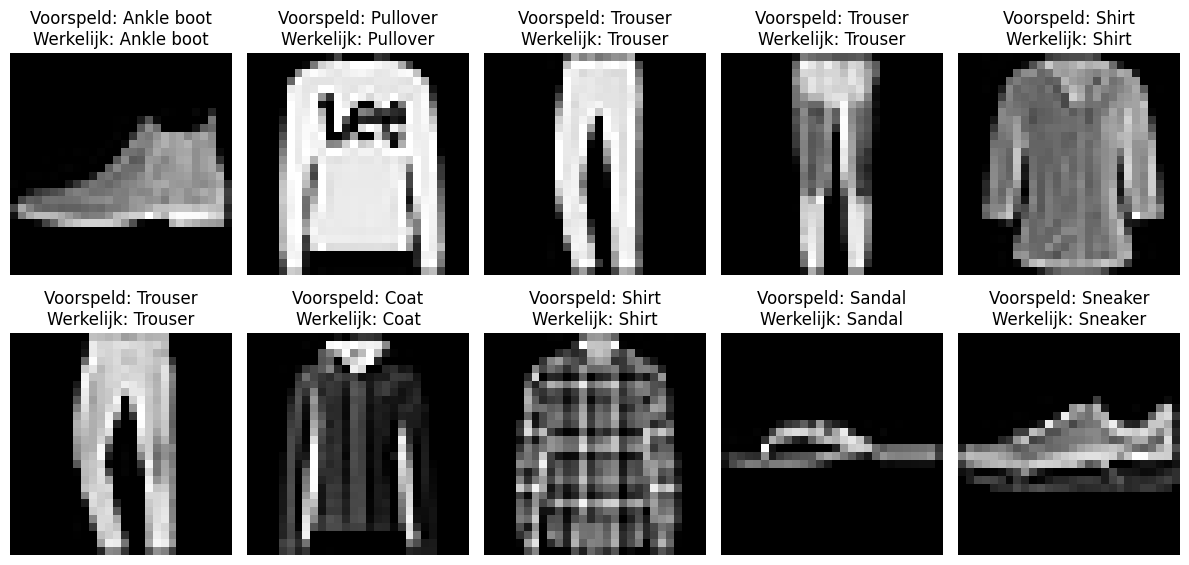

In [28]:
predictions = model.predict(X_test)

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i], cmap="gray")

    predicted_label = np.argmax(predictions[i])
    actual_label = y_test[i]

    plt.title(
        f"Voorspeld: {class_names[predicted_label]}\n"
        f"Werkelijk: {class_names[actual_label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In deze 10 is te zien dat hij alles op de juiste manier heeft voorspeld, ik ga even doorzoeken om te kijken of ik er ook een foute tussen kan zetten, want ik vind het wel interessant om te weten wat de fouten zijn van het model. Hiervoor voer ik het plotten iets anders uit door specifiek op 10 foute voorspellingen te indexeren:

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


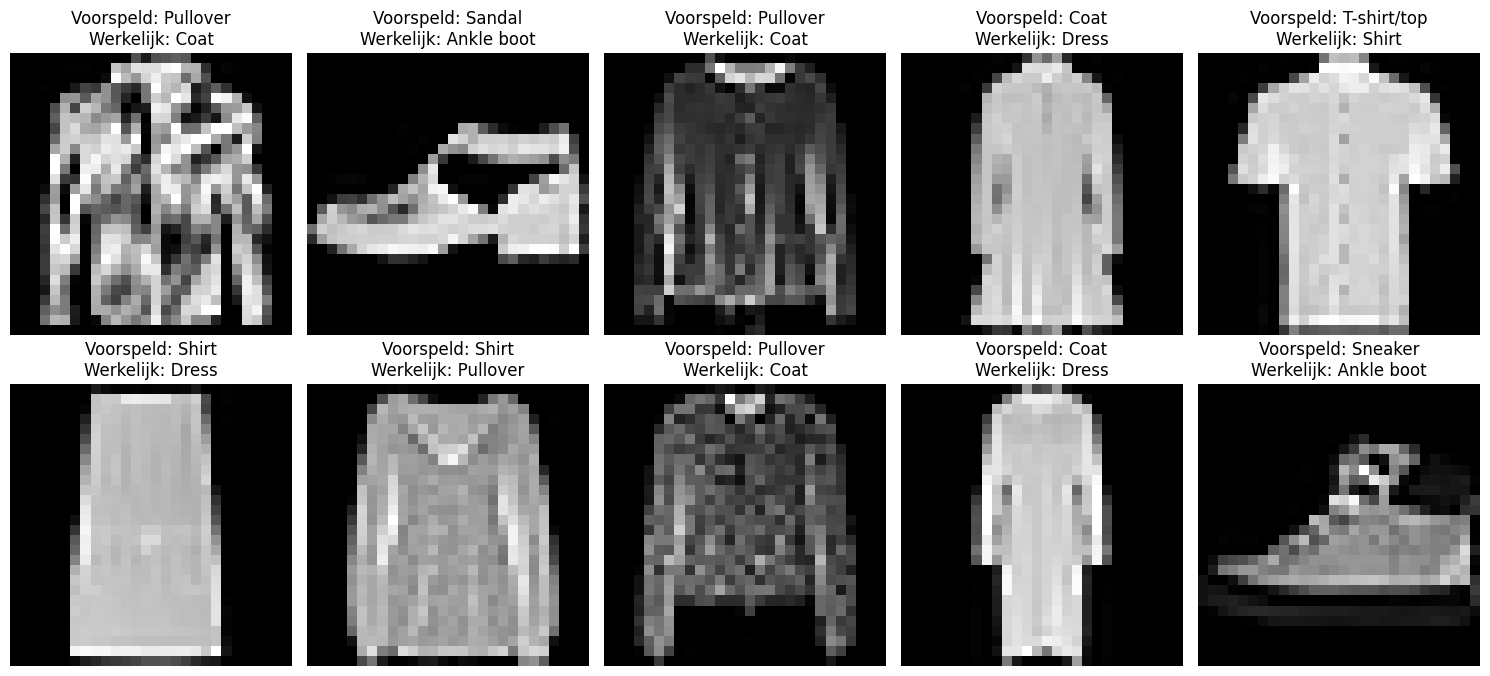

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Voorspellingen maken voor de volledige testset
predictions = model.predict(X_test)

# De voorspelde klasse bepalen
predicted_labels = np.argmax(predictions, axis=1)

# Indexen zoeken van foutieve voorspellingen
wrong_predictions = np.where(predicted_labels != y_test)[0]

# De eerste 10 foutieve voorspellingen selecteren
selected_images = wrong_predictions[:10]

# Afbeeldingen weergeven
plt.figure(figsize=(15, 7))

for i, index in enumerate(selected_images):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"Voorspeld: {class_names[predicted_labels[index]]}\n"
        f"Werkelijk: {class_names[y_test[index]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Dit zijn dus 10 fout voorspelde afbeeldingen, als je kijkt naar de voorspelling, de afbeelding en wat het daadwerkelijk moet zijn zie je eigenlijk wel dat dit hele logische fouten zijn, omdat alle voorspellingen nog redelijk lijken op wat in de afbeeldingen staat (geen schoen wordt voorspeld als jurk of iets in die richting).


#### Deel 2: eigen afbeelding